# Exploratory data analysis

In [21]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


ROOT = Path.cwd()
while not (ROOT / "src" / "config.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from config import COLUMNS, RAW_PATH, TARGET, TEST_START, WEATHER, DAYLIGHT_THRESHOLD
from pipeline import load, clean, to_hourly, add_features

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3})

## 1. Raw data: size, columns and date range

I loaded the raw dataset and reviewed its dimensions, column names, data types and time coverage. This gave me an overview of the available measurements and the period covered by the observations.

In [22]:
raw = pd.read_csv(RAW_PATH)
raw["time"] = pd.to_datetime(raw["time"], format="%d/%m/%Y %H:%M")

print(f"Rows: {len(raw):,}   Columns: {raw.shape[1]}")
print(f"From {raw['time'].min()} to {raw['time'].max()}")
raw.head()

C:\Users\mmaina\AppData\Local\Temp\ipykernel_15020\2468063113.py:1: DtypeWarning: Columns (14: comments) have mixed types. Specify dtype option on import or set low_memory=False.
  raw = pd.read_csv(RAW_PATH)


Rows: 567,360   Columns: 15
From 2019-12-04 00:01:00 to 2021-01-01 00:00:00


,time,dhi_pyr,ghi_pyr_1,ghi_pyr_2,air_temperature,relative_humidity,barometric_pressure,precipitation,wind_speed,wind_from_direction,gti_clean,gti_soil,gti_monthly,sensor_cleaning,comments
0,2019-12-04 00:01:00,0.00,0.00,0.00,15.60,97.78,811.29,0.00,1.25,243.79,0.00,0.00,0.00,0.00,NaN
1,2019-12-04 00:02:00,0.00,0.00,0.00,15.57,97.71,811.21,0.00,1.10,243.47,0.00,0.00,0.00,0.00,NaN
2,2019-12-04 00:03:00,0.00,0.00,0.00,15.57,97.71,811.22,0.00,0.60,231.84,0.00,0.00,0.00,0.00,NaN
3,2019-12-04 00:04:00,0.00,0.00,0.00,15.56,97.62,811.21,0.00,1.11,252.29,0.00,0.00,0.00,0.00,NaN
4,2019-12-04 00:05:00,0.00,0.00,0.00,15.53,97.59,811.21,0.00,0.54,232.00,0.00,0.00,0.00,0.00,NaN


In [23]:
raw.dtypes

time                   datetime64[us]
dhi_pyr                       float64
ghi_pyr_1                     float64
ghi_pyr_2                     float64
air_temperature               float64
relative_humidity             float64
barometric_pressure           float64
precipitation                 float64
wind_speed                    float64
wind_from_direction           float64
gti_clean                     float64
gti_soil                      float64
gti_monthly                   float64
sensor_cleaning               float64
comments                          str
dtype: object

## 2. Timestamps: duplicates and gaps

I checked the timestamps for duplicate records and compared the observed time intervals with the expected sampling frequency which helped me to identify gaps in the data and assess how complete the data coverage was.

In [24]:
dupes = raw["time"].duplicated().sum()
expected = int((raw["time"].max() - raw["time"].min()) / pd.Timedelta(minutes=1)) + 1
print(f"Duplicate timestamps: {dupes:,}")
print(f"Expected minutes in range: {expected:,}   Present: {raw['time'].nunique():,}")

step = raw["time"].sort_values().diff()
gaps = step[step > pd.Timedelta(minutes=1)]
print(f"Gaps in the timestamp sequence: {len(gaps):,}")
gaps.sort_values(ascending=False).head(10)

Duplicate timestamps: 0
Expected minutes in range: 567,360   Present: 567,360
Gaps in the timestamp sequence: 0


Series([], Name: time, dtype: timedelta64[us])

## 3. Missing values

I calculated the number and proportion of missing values in each column. I also examined how the availability of readings changed over time to identify periods when measurements were missing, including possible maintenance-related gaps.

In [25]:
missing = pd.DataFrame({
    "missing": raw.isna().sum(),
    "missing_%": raw.isna().mean() * 100,
}).sort_values("missing", ascending=False)
missing

,missing,missing_%
comments,478051,84.26
wind_from_direction,89281,15.74
wind_speed,70135,12.36
barometric_pressure,12573,2.22
air_temperature,12567,2.21
ghi_pyr_1,12553,2.21
relative_humidity,12552,2.21
gti_clean,12545,2.21
ghi_pyr_2,12545,2.21
dhi_pyr,12545,2.21


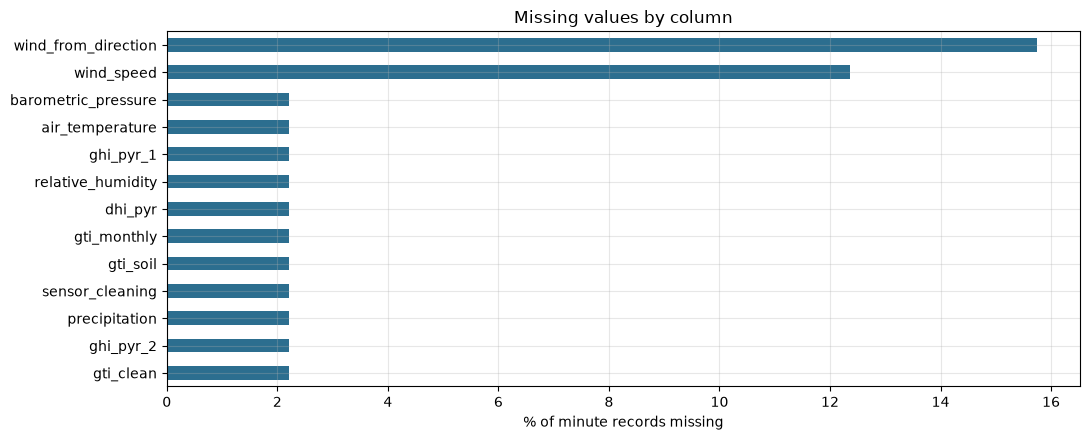

In [26]:
m = missing.drop(index=["time", "comments"], errors="ignore")
ax = m["missing_%"].sort_values().plot.barh(color="#2C6E8F")
ax.set_xlabel("% of minute records missing")
ax.set_title("Missing values by column")
save("01_missing_by_column")

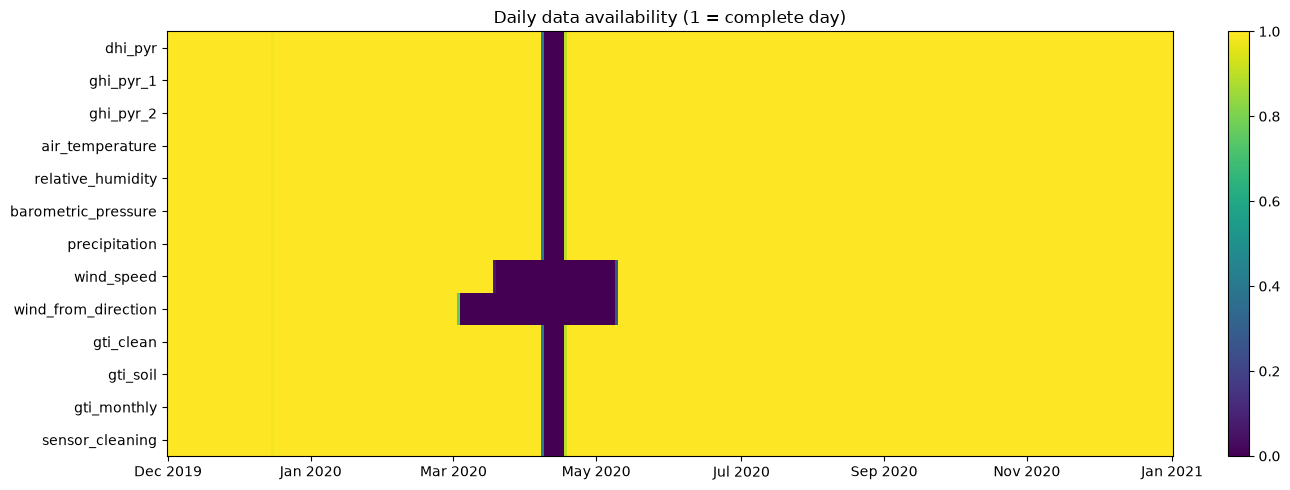

In [27]:
# Share of non-missing readings per day, for each variable: shows when maintenance gaps happened
cols = [c for c in raw.columns if c not in ("time", "comments")]
daily = raw.set_index("time")[cols].notna().resample("D").mean()

fig, ax = plt.subplots(figsize=(13, 5))
im = ax.imshow(daily.T.values, aspect="auto", cmap="viridis", vmin=0, vmax=1, interpolation="nearest")
ax.set_yticks(range(len(cols)))
ax.set_yticklabels(cols)
ticks = np.linspace(0, len(daily) - 1, 8).astype(int)
ax.set_xticks(ticks)
ax.set_xticklabels(daily.index[ticks].strftime("%b %Y"))
ax.grid(False)
ax.set_title("Daily data availability (1 = complete day)")
fig.colorbar(im, ax=ax, fraction=0.02)
save("02_daily_availability")

## 4. Sensor-cleaning flag and comments

I reviewed the sensor-cleaning flag and the comments recorded in the dataset. These fields provide context for interpreting unusual readings and periods when the sensors may have been cleaned or maintained.

In [28]:
print(raw["sensor_cleaning"].value_counts(dropna=False))
print()
print("Most common comments:")
raw["comments"].value_counts().head(10)

sensor_cleaning
0.00    554439
NaN      12545
1.00       376
Name: count, dtype: int64

Most common comments:


comments
Wind vane and anenometer damaged.                                                                                   57585
Wind vane damaged.                                                                                                  19144
Intermittent communication resulted in a gap in the data.                                                           12495
Data removed due to program upgrades/ station restart or failing quality check                                         48
Maintenance site visit conducted.                                                                                      24
Wind vane and anenometer damaged. Data removed due to program upgrades/ station restart or failing quality check       10
Wind vane damaged. Data removed due to program upgrades/ station restart or failing quality check                       3
Name: count, dtype: int64

## 5. Irradiance: distributions and night values

I compared the distributions of the available irradiance measurements and examined the target variable, `gti_clean`, in more detail. I also looked at readings during daylight hours and at small negative values recorded at night. These negative readings are consistent with a thermopile sensor offset; the preprocessing pipeline clips them to zero.

In [29]:
irr = ["gti_clean", "gti_soil", "gti_monthly", "ghi_pyr_1", "ghi_pyr_2", "dhi_pyr"]
summary = raw[irr].describe().T
summary["negative_count"] = (raw[irr] < 0).sum()
summary

,count,mean,std,min,25%,50%,75%,max,negative_count
gti_clean,"554,815.00",250.34,355.85,0.00,0.00,2.31,466.57,"1,611.78",0
gti_soil,"554,815.00",249.17,354.07,0.00,0.00,2.29,464.11,"1,611.23",0
gti_monthly,"554,815.00",247.76,352.18,0.00,0.00,2.32,461.15,"1,604.86",0
ghi_pyr_1,"554,807.00",265.96,373.33,0.00,0.00,2.39,501.97,"1,675.82",0
ghi_pyr_2,"554,815.00",265.73,373.63,0.00,0.00,1.19,501.52,"1,687.84",0
dhi_pyr,"554,815.00",87.24,132.65,0.00,0.00,2.34,128.70,775.09,0


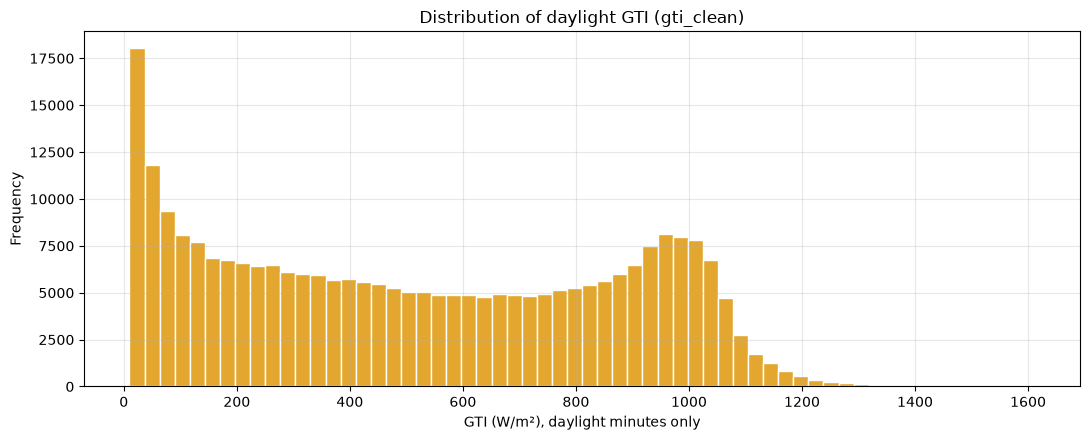

In [30]:
day = raw.loc[raw["gti_clean"] > DAYLIGHT_THRESHOLD, "gti_clean"]
ax = day.plot.hist(bins=60, color="#E3A72F", edgecolor="white")
ax.set_xlabel("GTI (W/m²), daylight minutes only")
ax.set_title("Distribution of daylight GTI (gti_clean)")
save("03_gti_distribution")

## 6. Leakage check

I examined the correlations between the target, `gti_clean`, and the other irradiance sensor measurements. The other irradiance sensors show very high contemporaneous correlations with the target because they measure closely related radiation conditions. I therefore excluded these measurements from the model features to avoid giving the model information that would not be appropriate for the intended prediction setup.

In [31]:
corr_target = raw[irr].corr()["gti_clean"].drop("gti_clean").sort_values(ascending=False)
corr_target.to_frame("correlation with gti_clean")

,correlation with gti_clean
gti_soil,1.00
gti_monthly,1.00
ghi_pyr_1,1.00
ghi_pyr_2,1.00
dhi_pyr,0.65


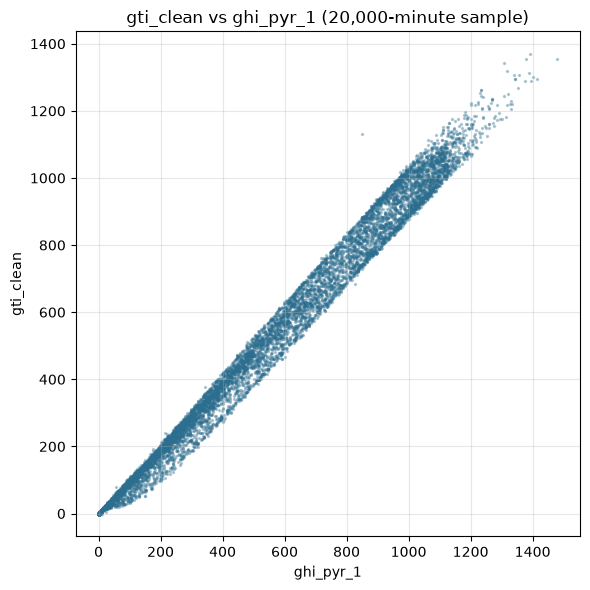

In [ ]:
sample = raw[["gti_clean", "ghi_pyr_1"]].dropna().sample(20_000, random_state=42)
ax = sample.plot.scatter(x="ghi_pyr_1", y="gti_clean", s=2, alpha=0.3, color="#2C6E8F", figsize=(6, 6))
ax.set_title("gti_clean vs ghi_pyr_1")
save("04_leakage_scatter")

## 7. Hourly data from the pipeline

This shows the cleaning, hourly aggregation and feature-engineering steps I used in `src/pipeline.py`. The resulting hourly dataset was used for the remaining analysis.

In [33]:
minute = clean(load())
hourly = to_hourly(minute)
final = add_features(hourly)

funnel = pd.Series({
    "raw minute records": len(raw),
    "after de-duplication": len(minute),
    "calendar hours": len(hourly),
    "hours with enough valid GTI minutes": int(hourly[TARGET].notna().sum()),
    "final modelling rows": len(final),
    "train rows": int((final.index < TEST_START).sum()),
    "test rows": int((final.index >= TEST_START).sum()),
}, name="rows")
funnel.to_frame()

,rows
raw minute records,567360
after de-duplication,567360
calendar hours,9457
hours with enough valid GTI minutes,9248
final modelling rows,7949
train rows,5741
test rows,2208


## 8. Daily cycle by month

I compared the average hourly GTI profile across months to examine how the daily irradiance cycle varied over the study period. This shows the typical pattern of GTI through the day and how that pattern changed between months.

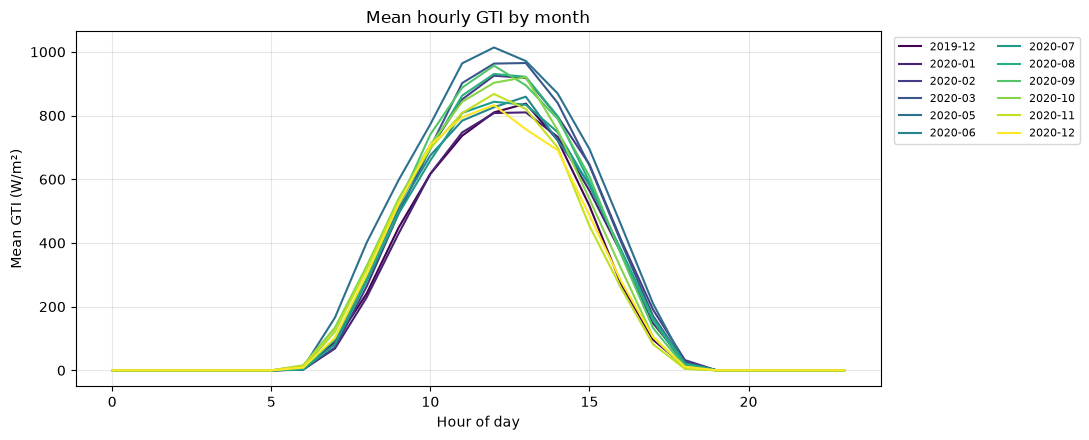

In [34]:
profile = final.groupby([final.index.to_period("M"), final.index.hour])[TARGET].mean().unstack(0)

fig, ax = plt.subplots()
cmap = plt.get_cmap("viridis", profile.shape[1])
for i, month in enumerate(profile.columns):
    ax.plot(profile.index, profile[month], color=cmap(i), label=str(month))
ax.set_xlabel("Hour of day")
ax.set_ylabel("Mean GTI (W/m²)")
ax.set_title("Mean hourly GTI by month")
ax.legend(ncol=2, fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
save("05_daily_cycle_by_month")

## 9. GTI over time and the train/test split

I plotted daily average GTI over the study period and marked the training and testing periods. This provided a visual check of the temporal split used in the modelling work and showed how irradiance varied over time.

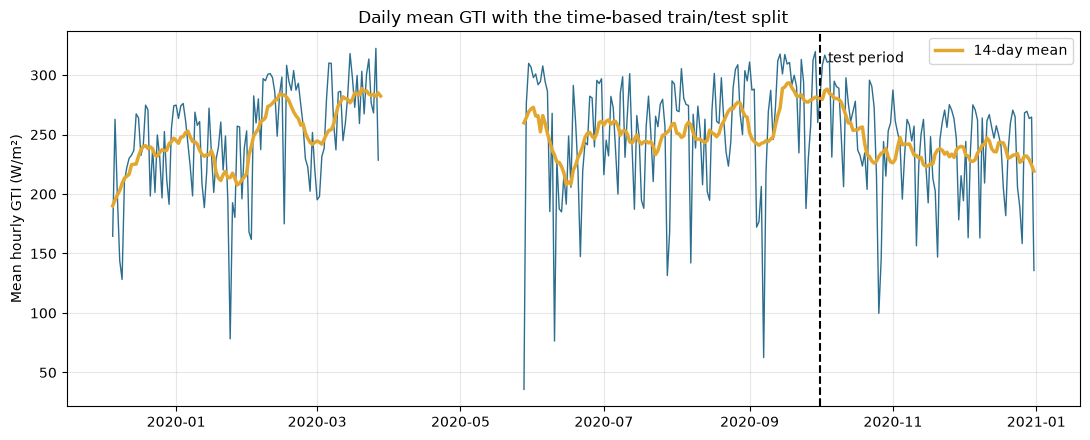

In [35]:
daily_gti = final[TARGET].resample("D").mean()

fig, ax = plt.subplots()
ax.plot(daily_gti.index, daily_gti, color="#2C6E8F", lw=1)
ax.plot(daily_gti.rolling(14, center=True, min_periods=7).mean(), color="#E3A72F", lw=2.5, label="14-day mean")
ax.axvline(pd.Timestamp(TEST_START), color="black", ls="--")
ax.text(pd.Timestamp(TEST_START), ax.get_ylim()[1] * 0.95, "  test period", va="top")
ax.set_ylabel("Mean hourly GTI (W/m²)")
ax.set_title("Daily mean GTI with the time-based train/test split")
ax.legend()
save("06_gti_over_time_split")

## 10. How weather relates to GTI

I explored the relationships between GTI and the weather variables used as model features. I examined both the overall correlations and selected relationships during daylight hours, when solar irradiance is relevant.

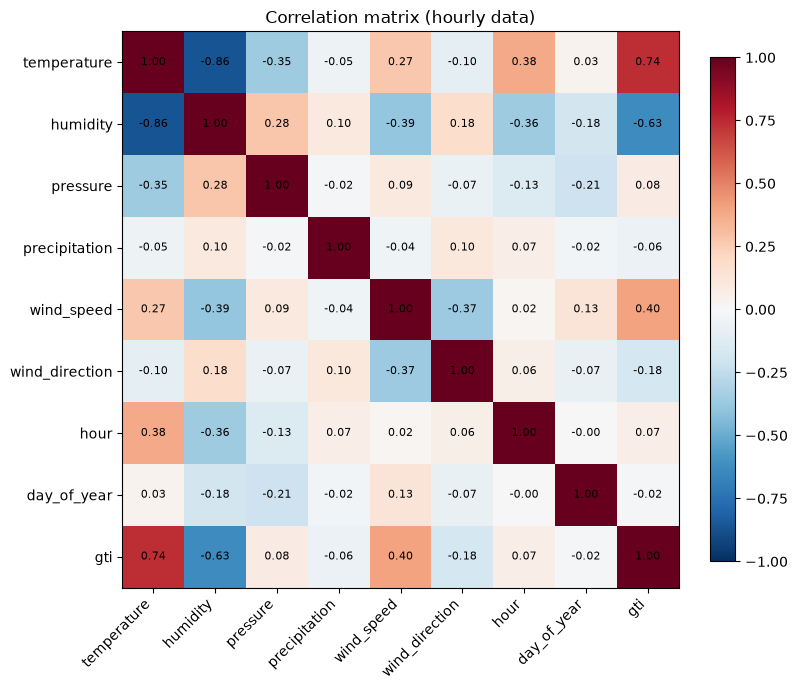

In [36]:
cols = WEATHER + ["hour", "day_of_year", TARGET]
c = final[cols].corr()

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols)))
ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.grid(False)
ax.set_title("Correlation matrix (hourly data)")
fig.colorbar(im, ax=ax, fraction=0.04)
save("07_correlation_matrix")

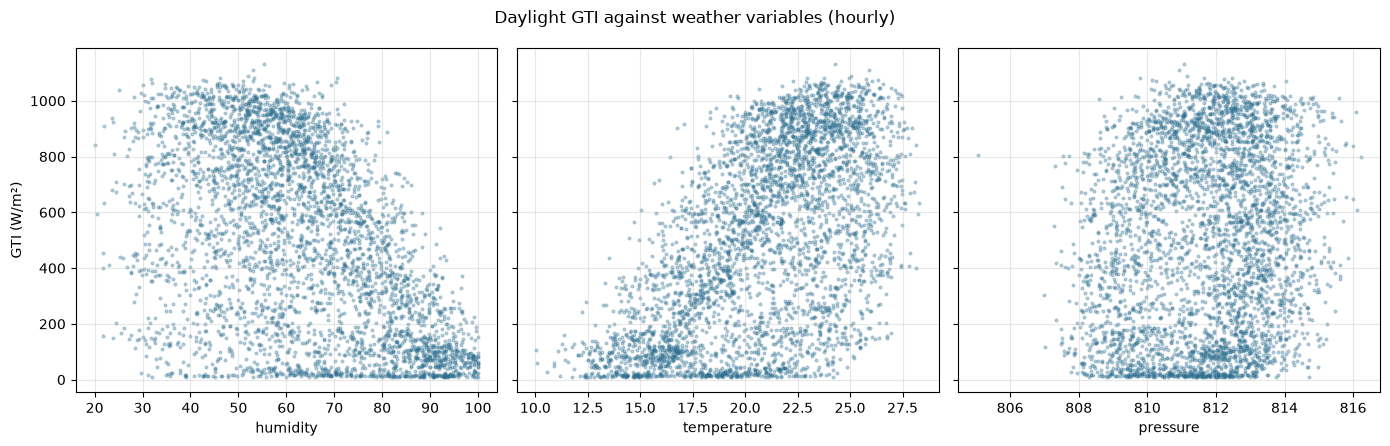

In [37]:
day_h = final[final[TARGET] > DAYLIGHT_THRESHOLD]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
for ax, col in zip(axes, ["humidity", "temperature", "pressure"]):
    ax.scatter(day_h[col], day_h[TARGET], s=4, alpha=0.3, color="#2C6E8F")
    ax.set_xlabel(col)
axes[0].set_ylabel("GTI (W/m²)")
fig.suptitle("Daylight GTI against weather variables (hourly)")
save("08_weather_scatter")

## 11. Autocorrelation: why lag-1 and lag-24 features

I calculated the autocorrelation of hourly GTI over the first 48 lags. This helped me examine how strongly current GTI readings were related to earlier hours, including the previous hour and the same hour on the previous day. The hourly series retains missing hours, so the analysis reflects the gaps in the observed time series.

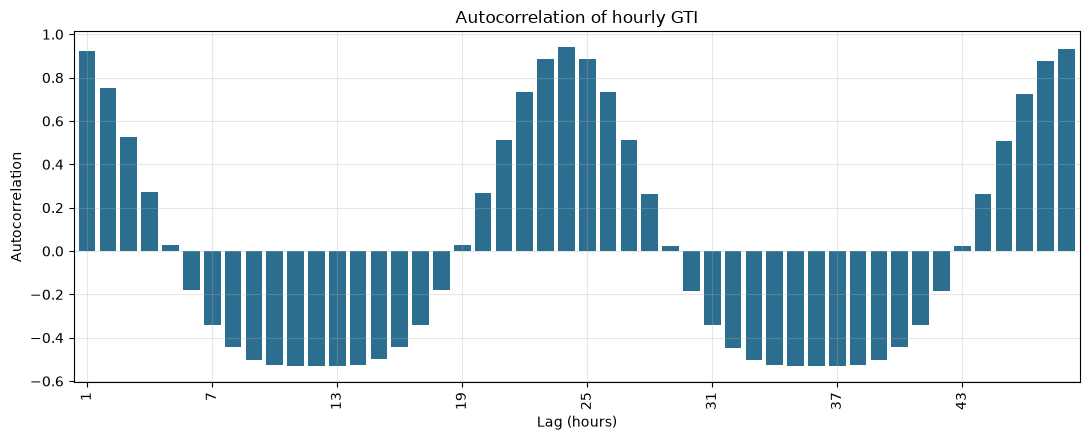

In [38]:
series = hourly[TARGET]
lags = range(1, 49)
acf = [series.autocorr(lag) for lag in lags]

ax = pd.Series(acf, index=lags).plot.bar(color="#2C6E8F", width=0.8)
ax.set_xticks(range(0, 48, 6))
ax.set_xticklabels(range(1, 49, 6))
ax.set_xlabel("Lag (hours)")
ax.set_ylabel("Autocorrelation")
ax.set_title("Autocorrelation of hourly GTI")
save("09_autocorrelation")